# Lesson 8.3: R-Squared and Residuals: Is the Line Any Good?

Measure how good the study-hours line is with R squared and adjusted R squared, and use the residuals to check the fit, for the lesson's eight students.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

The teacher has a line, score = 47.21 + 3.95 x hours, and two worries: how good is it (is 'about 82% explained' a lot?), and could the line be the wrong kind of model even when that number looks high? We use the same eight students to measure the fit with R squared and to inspect what the line missed (the residuals).

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: Fit the model with statsmodels

We fit the same line as in Lesson 8.2, but with statsmodels' formula interface, which gives the full summary. The formula 'score ~ hours' reads as 'score explained by hours'.

In [1]:
import numpy as np  # Load NumPy for numbers; we need its square root later.
import pandas as pd  # Load pandas, which holds data in tables (DataFrames).
import matplotlib.pyplot as plt  # Load matplotlib's plotting tools as plt for the residual plot.
import statsmodels.formula.api as smf  # Load statsmodels' formula interface, which fits regressions and prints full summaries.

df = pd.DataFrame({'hours': [1, 2, 3, 4, 5, 6, 7, 8],  # Build a table with a 'hours' column (1 to 8)...
                   'score': [48, 62, 55, 66, 63, 74, 70, 82]})  # ...and a 'score' column. Keeping both in one table lets us refer to them by name.

model = smf.ols('score ~ hours', data=df).fit()  # Fit ordinary least squares with the formula 'score ~ hours' (score explained by hours). .fit() does the calculation.

print(model.params.round(3))  # Print the intercept and slope rounded to 3 decimals. They should match Lesson 8.2.

Intercept    47.214
hours         3.952
dtype: float64


**What this means.** This is the same line as Lesson 8.2: score = 47.214 + 3.952 x hours. Fitting it with statsmodels means we can now ask for the extra measures of fit.

## Step 2: R squared and adjusted R squared

R squared is the share of the score variation that the line explains (0 to 1). Adjusted R squared is slightly lower: it charges a small penalty for each predictor, so it is fairer when comparing models.

In [2]:
print(f'R squared          = {model.rsquared:.3f}')  # R squared is the share of the variation in scores that the line explains, from 0 to 1.
print(f'adjusted R squared = {model.rsquared_adj:.3f}')  # Adjusted R squared charges a small penalty for each predictor, so it is fairer when comparing models.
print(f'residual std error = {np.sqrt(model.scale):.2f} points')  # The residual standard error is the typical size of a miss. model.scale is the residual variance, so we take its square root.

sse = (model.resid ** 2).sum()  # SSE, the sum of squared errors, adds up every student's squared miss. Least squares makes this as small as possible.
print(f'SSE = {sse:.1f}')  # Print SSE. It is the part of the variation the line does not explain.

R squared          = 0.822
adjusted R squared = 0.793
residual std error = 4.86 points
SSE = 141.9


**What this means.** R squared = 0.822: the line explains about 82% of the variation in scores. Adjusted R squared = 0.793 is slightly lower, as expected. The residual standard error is 4.86 points: a typical student lands about 5 points from the line. SSE = 141.9 is the variation left over.

## Step 3: Look at the residuals

A residual is what the line missed: actual minus predicted. Residuals should add up to about zero, and no student should be missed by a wildly larger amount than the rest.

In [3]:
df['fitted'] = model.fittedvalues  # Store each student's fitted (predicted) score in the table.
df['residual'] = model.resid  # Store each student's residual: actual score minus fitted score.

print(df.round(2).to_string(index=False))  # Print the table, rounded to 2 decimals, without the row numbers.
print(f'sum of residuals = {df.residual.sum():.6f}')  # The residuals of a least-squares line add up to zero. Print the sum as a check (up to rounding).

 hours  score  fitted  residual
     1     48   51.17     -3.17
     2     62   55.12      6.88
     3     55   59.07     -4.07
     4     66   63.02      2.98
     5     63   66.98     -3.98
     6     74   70.93      3.07
     7     70   74.88     -4.88
     8     82   78.83      3.17
sum of residuals = 0.000000


**What this means.** The residuals add up to 0, as they must. The biggest miss is student 2, who scored 62 but was predicted 55.12 (residual +6.88). The others miss by 3 to 5 points either way. No student is missed by a wildly larger amount, so no sign of an outlier.

## Step 4: Plot residuals against fitted values

If a straight line suits the data, the points scatter randomly around zero with no curve and no funnel shape. A visible pattern would warn us that the model is missing something.

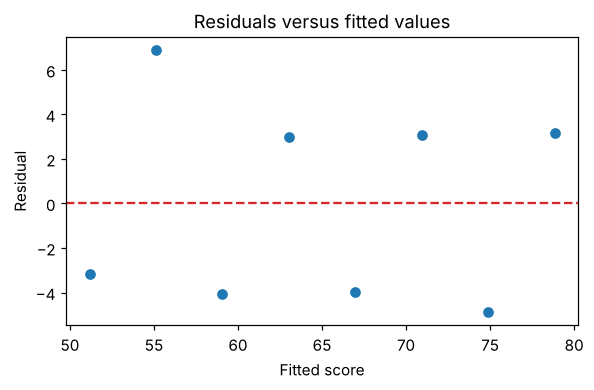

In [4]:
plt.figure(figsize=(6, 3.4))  # Start a new figure that fits the page.
plt.scatter(df.fitted, df.residual, color='#1f77b4')  # Plot each residual (vertical) against its fitted value (horizontal).
plt.axhline(0, color='#d62728', linestyle='--')  # Draw a dashed red line at 0, the 'no miss' level, as a reference.
plt.xlabel('Fitted score')  # Label the horizontal axis.
plt.ylabel('Residual')  # Label the vertical axis.
plt.title('Residuals versus fitted values')  # Add a title that says what the plot shows.
plt.show()  # Show the figure.

**What this means.** The points scatter above and below zero with no curve and no funnel shape. That is what we hope for: a straight line is a reasonable model here. With only eight students the plot is a rough guide, though, and a high R squared alone would not prove the line is the right shape.

## So, what is the answer?

The line is a good but not perfect summary: it explains about 82% of the variation in scores (R squared = 0.822, adjusted 0.793), and a typical student lands about 4.9 points from it. The residual plot shows no curve or funnel, so a straight line is a reasonable model. Caution: eight points is a small base for judging the shape, and R squared says nothing about cause.

## Now you try

A lab gives ten identical seedlings different doses of fertiliser (grams per pot, 1 to 10) and measures their growth in centimetres. Growth rises quickly at first, then levels off. A line gives a decent R squared, but is it the right model?

**Data:** dose = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
growth = [2.1, 3.9, 5.2, 6.1, 6.6, 6.9, 7.0, 7.2, 7.2, 7.3]

1. Fit a straight line of growth on dose and report the intercept and slope.
2. Report R squared and adjusted R squared.
3. List the residuals. Do their signs form a pattern?
4. Is a straight line a good model here?

*Hint:* Use sm.OLS(growth, sm.add_constant(dose)).fit(). For the pattern, look at the signs of the residuals in dose order.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np
import statsmodels.api as sm

dose = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
growth = np.array([2.1, 3.9, 5.2, 6.1, 6.6, 6.9, 7.0, 7.2, 7.2, 7.3])
model = sm.OLS(growth, sm.add_constant(dose)).fit()
print('intercept and slope:', model.params.round(3))
print(f'R squared = {model.rsquared:.3f}, adjusted = {model.rsquared_adj:.3f}')
print('residuals:', model.resid.round(2))
print('signs:', ''.join('+' if e > 0 else '-' for e in model.resid))

intercept and slope: [3.187 0.502]
R squared = 0.772, adjusted = 0.743
residuals: [-1.59 -0.29  0.51  0.9   0.9   0.7   0.3  -0.01 -0.51 -0.91]
signs: --+++++---


**Answer.** The line is growth = 3.187 + 0.502 x dose, with R squared = 0.772 and adjusted R squared = 0.743. The residual signs run --+++++---: negative at both ends and positive in the middle (for example -1.59 at dose 1). That is a curve the line misses, so a straight line is the wrong shape even though R squared looks decent. A curved model would fit better.

## The same question in R, SPSS and Stata

**R**

```r
hours <- c(1, 2, 3, 4, 5, 6, 7, 8)  # Store hours studied as a vector.
score <- c(48, 62, 55, 66, 63, 74, 70, 82)  # Store the exam scores in the same order.
fit <- lm(score ~ hours)  # Fit the linear model of score on hours.
summary(fit)  # summary prints the coefficients, R-squared, adjusted R-squared and the residual standard error together.
round(residuals(fit), 2)  # residuals(fit) gives each student's miss (actual minus fitted); round(..., 2) tidies them to 2 decimals.
plot(fitted(fit), residuals(fit)); abline(h = 0)  # Plot residuals against fitted values, then abline(h = 0) adds a reference line at zero. The semicolon lets two commands share a line.
```

How to read it: At the bottom of summary: Residual standard error: 4.863 on 6 degrees of freedom, Multiple R-squared: 0.8222, Adjusted R-squared: 0.7925. The residuals match Python (-3.17, 6.88, -4.07 and so on). In the plot, look for random scatter around 0 with no curve or fan.

**SPSS** (Analyze > Regression > Linear (Save: Residuals and Predicted values; Plots: *ZRESID on Y, *ZPRED on X))

```
DATA LIST FREE / hours score.
BEGIN DATA
1 48  2 62  3 55  4 66  5 63  6 74  7 70  8 82
END DATA.
REGRESSION
  /STATISTICS COEFF R ANOVA
  /DEPENDENT score
  /METHOD=ENTER hours
  /SCATTERPLOT=(*ZRESID ,*ZPRED)
  /SAVE PRED RESID.
```

How to read it: The Model Summary table shows R Square = .822, Adjusted R Square = .793 and Std. Error of the Estimate = 4.863. The new columns PRE_1 and RES_1 hold the fitted values and residuals. In the plot, look for random scatter around 0, as in Python.

**Stata**

```
clear
set obs 8
generate hours = _n
generate score = real(word("48 62 55 66 63 74 70 82", _n))
regress score hours
predict fitted, xb
predict resid, residuals
list hours score fitted resid
rvfplot, yline(0)
```

How to read it: In the regress output find R-squared = 0.8222, Adj R-squared = 0.7925 and Root MSE = 4.863 (the residual standard error). The list shows the residuals (for example 6.88 for student 2). In the rvfplot, look for random scatter around the line at 0.